# baseline et premier modèle

données nettoyées avec `scripts/clean_data.py`.

In [1]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

train = pd.read_parquet("../data/train/train.parquet")
test = pd.read_parquet("../data/test/test.parquet")

classes = list("ABCDEFG")
vers_chiffre = {c: i for i, c in enumerate(classes)}  # a=0 ... g=6
y_train = train["classe"].map(vers_chiffre).to_numpy()
y_test = test["classe"].map(vers_chiffre).to_numpy()

## les 3 notes (metrics)

- **exactitude (accuracy)** : % de classes exactement justes
- **à une classe près** : % de prédictions à au plus une lettre d'écart
- **f1 macro** : donne autant de poids aux classes rares (a, b, g) qu'aux fréquentes

et pour la question « passoire ou pas ? » (f ou g) :
- **précision (precision)** : quand le modèle dit « passoire », % de fois où c'est vrai
- **rappel (recall)** : parmi les vraies passoires, % que le modèle trouve

In [2]:
def notes(vrai, predit):
    passoire_vrai = vrai >= 5   # f=5, g=6
    passoire_predit = predit >= 5
    return {
        "exactitude": round(accuracy_score(vrai, predit), 3),
        "à une classe près": round(np.mean(np.abs(predit - vrai) <= 1), 3),
        "f1 macro": round(f1_score(vrai, predit, average="macro"), 3),
        "passoire précision": round(precision_score(passoire_vrai, passoire_predit), 3),
        "passoire rappel": round(recall_score(passoire_vrai, passoire_predit), 3),
    }

## 1. baseline : la règle la plus simple

pour chaque combinaison (période × énergie de chauffage), on prédit la classe la plus fréquente dans l'entraînement.

In [3]:
plus_frequente = train.groupby(["periode", "energie"])["classe"].agg(lambda s: s.mode()[0])
classe_generale = train["classe"].mode()[0]  # si une combinaison n'existe pas dans l'entraînement

pred_baseline = (test.set_index(["periode", "energie"]).index.map(plus_frequente)
                 .fillna(classe_generale).map(vers_chiffre).to_numpy())
resultats = {"baseline": notes(y_test, pred_baseline)}
pd.DataFrame(resultats)

,baseline
exactitude,0.444
à une classe près,0.864
f1 macro,0.279
passoire précision,0.526
passoire rappel,0.247


## 2. le vrai modèle : xgboost dans un pipeline

le pipeline transforme les textes en chiffres (one-hot encoding), puis entraîne xgboost.

In [4]:
nombres = ["surface", "niveaux", "hauteur", "apres_2026"]
textes = ["periode", "type_batiment", "energie", "installation", "equipement",
          "energie_eau_chaude", "departement", "altitude"]


def creer_modele(colonnes_texte):
    return Pipeline([
        ("prep", ColumnTransformer(
            [("texte", OneHotEncoder(handle_unknown="ignore"), colonnes_texte)],
            remainder="passthrough",
        )),
        ("xgb", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=4)),
    ])


modele = creer_modele(textes)
modele.fit(train[nombres + textes], y_train)
pred = modele.predict(test[nombres + textes])
resultats["modèle"] = notes(y_test, pred)
pd.DataFrame(resultats)

,baseline,modèle
exactitude,0.444,0.494
à une classe près,0.864,0.887
f1 macro,0.279,0.374
passoire précision,0.526,0.615
passoire rappel,0.247,0.232


## 3. avec ou sans l'équipement de chauffage ?

In [5]:
sans = [t for t in textes if t != "equipement"]
modele_sans = creer_modele(sans)
modele_sans.fit(train[nombres + sans], y_train)
resultats["modèle sans équipement"] = notes(y_test, modele_sans.predict(test[nombres + sans]))
pd.DataFrame(resultats)

,baseline,modèle,modèle sans équipement
exactitude,0.444,0.494,0.490
à une classe près,0.864,0.887,0.883
f1 macro,0.279,0.374,0.364
passoire précision,0.526,0.615,0.616
passoire rappel,0.247,0.232,0.232


## 4. où le modèle se trompe-t-il ? (confusion matrix)

ligne = vraie classe, colonne = classe prédite.

In [6]:
pd.DataFrame(confusion_matrix(y_test, pred), index=classes, columns=classes)

,A,B,C,D,E,F,G
A,479,121,219,43,4,0,0
B,189,387,1818,417,19,0,5
C,72,200,13787,5758,323,18,41
D,4,19,5424,10457,1048,140,110
E,0,2,1145,5681,1474,286,196
F,0,1,220,1897,756,409,216
G,0,0,84,842,409,264,385


## 5. plus de données = meilleur modèle ? (learning curve)

on entraîne sur des parts de plus en plus grandes, et on regarde si la note monte encore.

,exactitude,à une classe près,f1 macro,passoire précision,passoire rappel
25000,0.475,0.876,0.353,0.561,0.223
50000,0.486,0.880,0.364,0.596,0.234
100000,0.492,0.885,0.370,0.612,0.228
221473,0.494,0.887,0.374,0.615,0.232


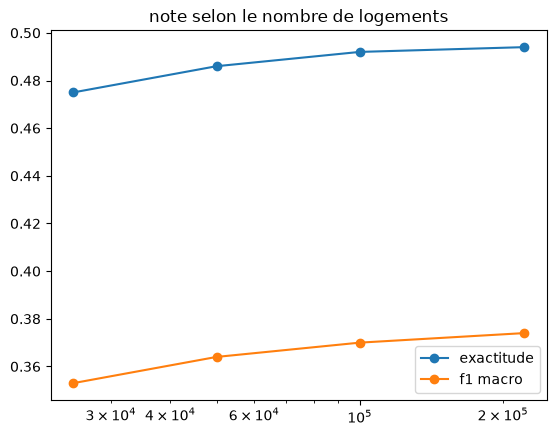

In [7]:
courbe = {}
for n in [25_000, 50_000, 100_000, len(train)]:
    part = train.sample(n, random_state=42)
    m = creer_modele(textes)
    m.fit(part[nombres + textes], part["classe"].map(vers_chiffre))
    courbe[n] = notes(y_test, m.predict(test[nombres + textes]))
courbe = pd.DataFrame(courbe).T
courbe[["exactitude", "f1 macro"]].plot(marker="o", logx=True, title="note selon le nombre de logements")
courbe

## 6. donner plus de poids aux classes rares (class weights)

on dit au modèle : « te tromper sur un logement d'une classe rare (a, b, f, g) coûte plus cher ».

- **équilibré (balanced)** : chaque classe pèse autant au total. une classe 10 fois plus rare compte 10 fois plus.
- **adouci (softened)** : même idée, mais moins fort (racine carrée du poids).

In [8]:
from sklearn.utils.class_weight import compute_sample_weight

poids = compute_sample_weight("balanced", y_train)

for nom, p in [("modèle équilibré", poids), ("modèle adouci", np.sqrt(poids))]:
    m = creer_modele(textes)
    m.fit(train[nombres + textes], y_train, xgb__sample_weight=p)
    resultats[nom] = notes(y_test, m.predict(test[nombres + textes]))

pd.DataFrame(resultats)

,baseline,modèle,modèle sans équipement,modèle équilibré,modèle adouci
exactitude,0.444,0.494,0.490,0.374,0.475
à une classe près,0.864,0.887,0.883,0.739,0.865
f1 macro,0.279,0.374,0.364,0.347,0.409
passoire précision,0.526,0.615,0.616,0.284,0.456
passoire rappel,0.247,0.232,0.232,0.739,0.414
